In [ ]:
# Persiapan tambahan notebook.
import sys
import time
import hashlib
import urllib.request
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from numpy.lib.stride_tricks import sliding_window_view

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
try:
    from threadpoolctl import threadpool_limits
    blas_limiter = threadpool_limits(limits=1)
    print('BLAS dibatasi ke satu thread untuk eksperimen NumPy ini.')
except ImportError:
    print('threadpoolctl tidak tersedia; memakai pengaturan BLAS lingkungan.')
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Matplotlib:', matplotlib.__version__)

BLAS dibatasi ke satu thread untuk eksperimen NumPy ini.
Python: 3.13.16
NumPy: 2.1.3
Matplotlib: 3.10.0


## 2. Ringkasan dan peta Chapter 10

Buku memperkenalkan **structure** sebagai cara memasukkan asumsi ke dalam arsitektur. Jika pola seperti garis dapat muncul di banyak bagian gambar, model dapat mencari pola itu dengan bobot yang sama pada setiap lokasi. Dibandingkan membuat detektor terpisah untuk tiap lokasi, weight sharing memberi satu kernel kesempatan menerima kontribusi belajar dari banyak patch.

Convolutional layer memakai receptive field lokal, yaitu sebagian kecil input yang dilihat sebuah unit. Banyak kernel menghasilkan banyak feature map. Kernel 3 × 3 pada gambar grayscale mempunyai sembilan bobot, lalu digunakan berulang saat melintasi gambar. Feature map tetap menyimpan informasi lokasi respons.

Untuk implementasi NumPy, setiap patch dikumpulkan menjadi matriks. Semua patch dikalikan dengan matriks kernel yang sama. Output diubah bentuknya per gambar, dilewatkan ke tanh, dropout, lalu classifier dense dengan softmax. Gradien kernel menjumlahkan kontribusi dari seluruh lokasi tempat parameter yang sama digunakan.

| Subbab buku | Halaman cetak | Pengerjaan |
| --- | --- | --- |
| Reusing weights in multiple places | 178 | Structure, asumsi spasial, dan parameter sharing |
| The convolutional layer | 179-180 | Kernel, receptive field, feature map, dan pooling |
| A simple implementation in NumPy | 181-184 | Ekstraksi patch, reshape, reproduksi 300 epoch, dan backpropagation |
| Summary / The structure trick | 185 | Shared intelligence, susunan layer, dan batas klaim generalisasi |

Rumus output size, cross-correlation, pooling spatial, finite difference, validation tambahan, serta trainer dengan gradien konsisten adalah pendalaman. Contoh visual memakai input dan kernel yang dijelaskan asalnya; kernel buatan untuk demonstrasi tidak dinyatakan sebagai hasil training.

## 3. Structure, locality, dan weight sharing

Pada dense layer, setiap hidden unit dapat memiliki bobot ke seluruh pixel. Pada convolutional layer, sebuah unit hanya melihat patch kecil, tetapi **kernel yang sama** digunakan lagi pada lokasi lain. Dua asumsi yang dimasukkan adalah:

- **Locality:** feature awal dapat dipelajari dari hubungan pixel yang berdekatan.
- **Weight sharing:** detektor pola berguna di lebih dari satu posisi.

Asumsi ini disebut inductive bias: membatasi kelas fungsi yang dapat dipilih model agar sesuai struktur data. Pengurangan parameter tidak menjamin hilangnya overfitting, dan CNN tidak memiliki semua kemampuan jaringan dense tak-terbatas dengan ukuran lain. Manfaatnya muncul ketika asumsi tersebut cocok dengan masalah.

Patch yang overlap bukan sampel independen baru. Meskipun shared kernel menerima banyak kontribusi gradien, mengambil lebih banyak patch tidak mengubah 896 gambar menjadi ratusan ribu gambar independen. Evaluasi generalisasi tetap perlu dilakukan pada gambar yang tidak digunakan untuk update.

Parameter yang sama bukan berarti semua kernel sama. Enam belas kernel mempunyai bobot berbeda; masing-masing diulang pada seluruh posisi. Pada gambar RGB, satu kernel biasanya mencakup semua channel input. Jumlah parameter convolution tanpa bias adalah $k_hk_wC_{\mathrm{in}}C_{\mathrm{out}}$; bias, bila digunakan, menambah $C_{\mathrm{out}}$.

**Rujukan utama:** Trask (2019), hlm. 178-180, 185. Penjelasan inductive bias dan dependensi patch adalah pendalaman.

## 4. Kernel, feature map, dan ukuran output

Untuk grayscale dan stride satu tanpa padding:

$$Z_{b,r,c,f}=\sum_{u=0}^{k_h-1}\sum_{v=0}^{k_w-1}
X_{b,r+u,c+v}K_{u,v,f}.$$

Satu kernel menghasilkan satu feature map. Banyak kernel memberi beberapa channel output. Aktivasi seperti tanh diterapkan setelah jumlah tersebut; tanpa aktivasi, operasi kernel adalah linear.

Rumus umum dengan stride $S$, padding $P$, dan dilation satu adalah:

$$H_{\mathrm{out}}=\left\lfloor\frac{H+2P-k_h}{S}\right\rfloor+1,\qquad
W_{\mathrm{out}}=\left\lfloor\frac{W+2P-k_w}{S}\right\rfloor+1.$$

Padding nol menambah area batas; stride mengatur langkah perpindahan. Dilation lebih dari satu mengganti ukuran kernel efektif menjadi $d(k_h-1)+1$ dan $d(k_w-1)+1$. Program sumber tidak memakai padding, dilation, bias, atau pooling.

Ilustrasi buku: gambar 8 × 8 dan kernel 3 × 3 menghasilkan 6 × 6. Untuk MNIST 28 × 28, rumus valid standar menghasilkan **26 × 26**. Akan tetapi, listing memakai `range(28-3)`, yaitu start 0-24, sehingga hanya menghasilkan **25 × 25**. Start 25 tidak dipakai; akibatnya pixel pada baris atau kolom indeks 27 tidak terlihat oleh kernel. Reproduksi mempertahankan geometri ini.

Istilah convolution pada implementasi jaringan sering merujuk pada **cross-correlation**, karena kernel tidak dibalik. Convolution matematis membalik kernel pada kedua sumbu spatial. Keduanya dapat memakai kernel yang dilatih; yang penting adalah definisi forward dan backward konsisten.

**Rujukan:** Trask (2019), hlm. 179-184; rumus dan definisi matematis tambahan.

In [ ]:
# Pendalaman ukuran output dan batas loop sumber.
def output_size(length, kernel_size, stride=1, padding=0, dilation=1):
    effective_kernel = dilation*(kernel_size-1)+1
    return (length+2*padding-effective_kernel)//stride+1

print('8×8, kernel 3×3, valid:', output_size(8, 3), '×', output_size(8, 3))
print('28×28, kernel 3×3, valid standar:', output_size(28, 3), '×', output_size(28, 3))
print('Geometri loop sumber:', len(range(28-3)), '×', len(range(28-3)))
print('28×28, kernel 3×3, padding 1:', output_size(28, 3, padding=1))
print('28×28, kernel 3×3, stride 2:', output_size(28, 3, stride=2))
assert output_size(8, 3) == 6
assert output_size(28, 3) == 26
assert output_size(28, 3, padding=1) == 28

8×8, kernel 3×3, valid: 6 × 6
28×28, kernel 3×3, valid standar: 26 × 26
Geometri loop sumber: 25 × 25
28×28, kernel 3×3, padding 1: 28
28×28, kernel 3×3, stride 2: 13


## 5. Demonstrasi kernel 3 × 3 dari ilustrasi buku

Kernel yang ditampilkan pada hlm. 179 mempunyai semua bobot nol kecuali satu pada sudut kanan bawah. Dengan cross-correlation, kernel tersebut mengambil pixel kanan bawah dari setiap patch; kernel ini bukan detektor edge yang lengkap.

Sel berikut menggunakan kernel tersebut pada **gambar biner 8 × 8 angka 2 yang dikonstruksi untuk notebook**. Input ini membantu melihat posisi tanpa menganggap nilai pixel ilustrasi buku telah diberikan secara numerik. Direct loop dan perkalian matriks patch diperiksa agar menghasilkan respons yang sama.

Kernel edge pada bagian berikut dibuat untuk menjelaskan operasi lokal, sedangkan kernel hasil training ditampilkan di bagian akhir. Respons kernel linear dapat positif, negatif, atau nol; tidak selalu berupa keputusan 0/1.

In [ ]:
# Fungsi direct cross-correlation tambahan, valid, grayscale, tanpa bias.
def direct_valid_correlation(batch_images, kernel_bank):
    B, H, W = batch_images.shape
    kh, kw, F = kernel_bank.shape
    result = np.empty((B, H-kh+1, W-kw+1, F), dtype=np.float64)
    for b in range(B):
        for r in range(H-kh+1):
            for c in range(W-kw+1):
                patch = batch_images[b, r:r+kh, c:c+kw]
                result[b, r, c] = np.sum(patch[:, :, None]*kernel_bank, axis=(0, 1))
    return result

toy_digit = np.array([
    [0, 0, 1, 1, 1, 0, 0, 0],
    [0, 1, 0, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
], dtype=float)
book_illustration_kernel = np.zeros((3, 3, 1))
book_illustration_kernel[2, 2, 0] = 1
illustration_map = direct_valid_correlation(toy_digit[None], book_illustration_kernel)[0, :, :, 0]
assert illustration_map.shape == (6, 6)
assert np.array_equal(illustration_map, toy_digit[2:, 2:])
print('Kernel pada ilustrasi hlm. 179:\n', book_illustration_kernel[:, :, 0])
print('Feature map 6×6:\n', illustration_map)

Kernel pada ilustrasi hlm. 179:
 [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 1.]]
Feature map 6×6:
 [[0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 1. 1. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]


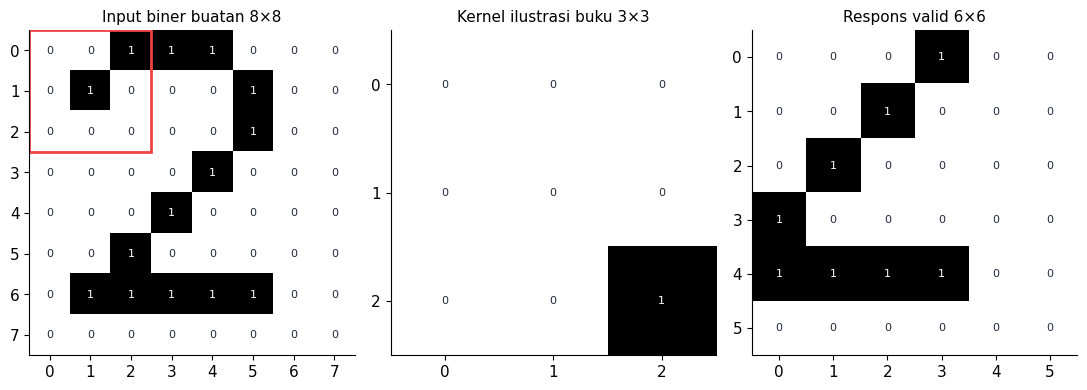

In [ ]:
# Grafik 1: input, kernel sumber, dan respons valid 6×6.
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, data, title in zip(axes, [toy_digit, book_illustration_kernel[:, :, 0], illustration_map],
                          ['Input biner buatan 8×8', 'Kernel ilustrasi buku 3×3', 'Respons valid 6×6']):
    ax.imshow(data, cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(title, fontsize=11)
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    for r in range(data.shape[0]):
        for c in range(data.shape[1]):
            ax.text(c, r, str(int(data[r, c])), ha='center', va='center', fontsize=8,
                    color='white' if data[r, c] > 0.5 else '#1e293b')
axes[0].add_patch(Rectangle((-0.5, -0.5), 3, 3, fill=False, edgecolor='#ef4444', linewidth=2))
fig.tight_layout()
plt.show()

## 6. Banyak kernel mencari pola berbeda

Setiap kernel mempunyai sembilan bobot sendiri, tetapi bobot tersebut digunakan lagi di seluruh lokasi. Empat kernel buatan berikut menanggapi perbedaan pixel pada arah berbeda. Dua kernel adalah operator Sobel sederhana untuk perbedaan horizontal/vertical; dua lainnya merupakan contoh bobot diagonal dan sudut.

Nama kernel menerangkan konstruksi bobotnya, bukan label yang diberikan setelah training. Respons besar terjadi ketika patch selaras dengan pola bobot. Mengalikan kernel dengan -1 akan membalik tanda respons; interpretasi juga perlu melihat nilai pixel dan aktivasi yang digunakan.

**Rujukan:** Trask (2019), hlm. 179-180; matriks dan perhitungan berikut adalah demonstrasi tambahan.

Empat feature map: (6, 6, 4)


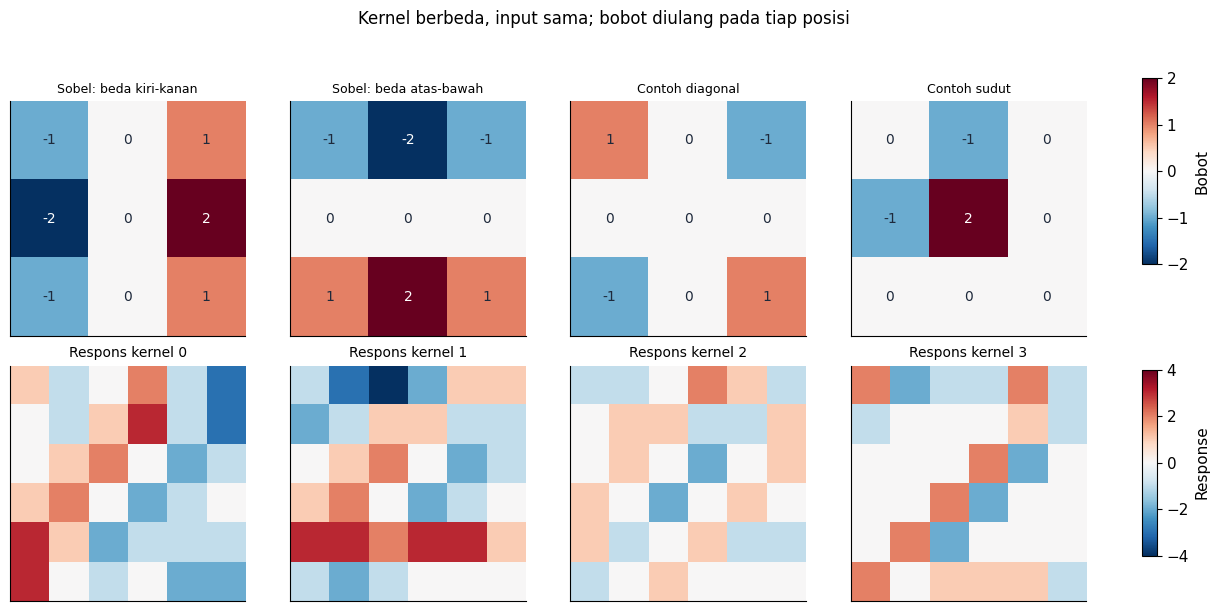

In [ ]:
# Demonstrasi tambahan: bank empat kernel buatan, bukan kernel hasil training.
demo_kernels = np.stack([
    np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    np.array([[1, 0, -1], [0, 0, 0], [-1, 0, 1]]),
    np.array([[0, -1, 0], [-1, 2, 0], [0, 0, 0]]),
], axis=2).astype(float)
demo_kernel_names = ['Sobel: beda kiri-kanan', 'Sobel: beda atas-bawah',
                     'Contoh diagonal', 'Contoh sudut']
demo_maps = direct_valid_correlation(toy_digit[None], demo_kernels)[0]
print('Empat feature map:', demo_maps.shape)
assert demo_maps.shape == (6, 6, 4)

# Grafik 2: tiap kernel mempunyai map-nya sendiri.
fig, axes = plt.subplots(2, 4, figsize=(12.5, 6.2))
for f in range(4):
    kernel_image = axes[0, f].imshow(demo_kernels[:, :, f], cmap='RdBu_r', vmin=-2, vmax=2)
    axes[0, f].set_title(demo_kernel_names[f], fontsize=9)
    for r in range(3):
        for c in range(3):
            axes[0, f].text(c, r, str(int(demo_kernels[r, c, f])), ha='center', va='center', fontsize=10,
                            color='white' if abs(demo_kernels[r, c, f]) > 1 else '#1e293b')
    response_image = axes[1, f].imshow(demo_maps[:, :, f], cmap='RdBu_r', vmin=-4, vmax=4)
    axes[1, f].set_title(f'Respons kernel {f}', fontsize=10)
    for ax in axes[:, f]:
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle('Kernel berbeda, input sama; bobot diulang pada tiap posisi', fontsize=12)
fig.tight_layout(rect=(0, 0, 0.91, 0.94))
kernel_cax = fig.add_axes([0.93, 0.57, 0.012, 0.30])
response_cax = fig.add_axes([0.93, 0.10, 0.012, 0.30])
fig.colorbar(kernel_image, cax=kernel_cax, label='Bobot')
fig.colorbar(response_image, cax=response_cax, label='Response')
plt.show()

## 7. Pooling: tentukan sumbu yang direduksi

Narasi hlm. 180 menjelaskan sum/mean/max **antar-kernel pada posisi yang sama**. Untuk empat map 6 × 6, operasi itu mengubah bentuk $(6,6,4)$ menjadi $(6,6)$. Ini adalah reduksi channel seperti yang ditampilkan pada ilustrasi sumber.

Spatial pooling yang umum pada CNN mereduksi area dalam **masing-masing channel**. Contohnya max pooling 2 × 2, stride 2, mengubah $(6,6,4)$ menjadi $(3,3,4)$, sehingga jumlah channel tetap empat. Operasi ini berbeda dari mengambil maksimum antar-kernel. Kode MNIST lengkap buku sendiri **tidak memakai pooling**; seluruh feature map langsung di-flatten.

Mean dan sum membagikan gradien pada elemen yang digabung; sum memberi multiplier 1 dan mean memberi $1/n$. Max meneruskan gradien hanya pada elemen yang dipilih sebagai maksimum. Jika ada tie, perlu kebijakan pembagian/pemilihan subgradient. Spatial pooling dapat menambah toleransi terhadap perubahan posisi kecil, tetapi tidak menjamin invariance sempurna dan dapat membuang detail spatial.

**Rujukan:** Trask (2019), hlm. 180 untuk reduksi antar-kernel; [catatan CNN Stanford CS231n](https://cs231n.github.io/convolutional-networks/) untuk pooling spatial. Contoh berikut membedakan sumbunya secara eksplisit.

Sum/mean/max antar-channel: (6, 6)
Max pooling spatial 2×2 stride 2: (3, 3, 4)
Spatial pooling channel 0:
 [[ 1.  3. -1.]
 [ 2.  2.  0.]
 [ 3.  0. -1.]]


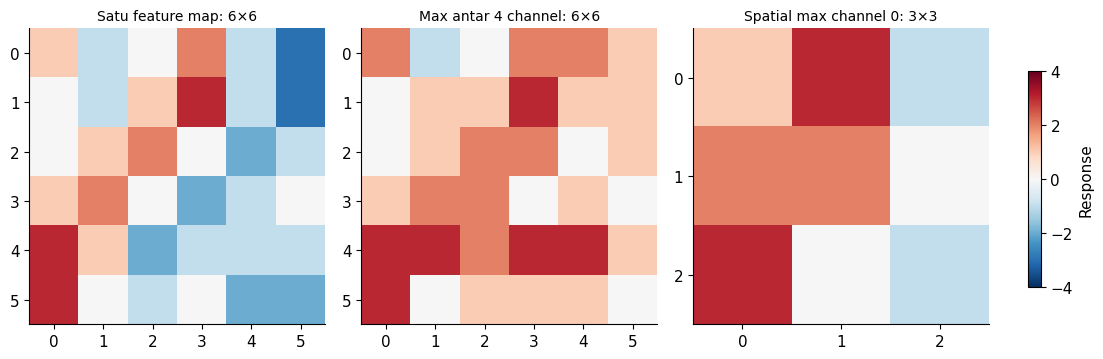

In [ ]:
# Pendalaman: reduksi channel berbeda dari pooling spatial.
channel_sum = demo_maps.sum(axis=2)
channel_mean = demo_maps.mean(axis=2)
channel_max = demo_maps.max(axis=2)
# (3, 2, 3, 2, 4) -> reduce kedua sumbu window, sehingga channel tetap.
spatial_max = demo_maps.reshape(3, 2, 3, 2, 4).max(axis=(1, 3))
assert channel_max.shape == (6, 6)
assert spatial_max.shape == (3, 3, 4)
assert np.allclose(channel_sum, channel_mean*4)
print('Sum/mean/max antar-channel:', channel_max.shape)
print('Max pooling spatial 2×2 stride 2:', spatial_max.shape)
print('Spatial pooling channel 0:\n', spatial_max[:, :, 0])

# Grafik 3: sumbu yang berbeda menghasilkan bentuk berbeda.
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, data, title in zip(axes, [demo_maps[:, :, 0], channel_max, spatial_max[:, :, 0]],
                          ['Satu feature map: 6×6', 'Max antar 4 channel: 6×6',
                           'Spatial max channel 0: 3×3']):
    pooling_image = ax.imshow(data, cmap='RdBu_r', vmin=-4, vmax=4)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
fig.tight_layout(rect=(0, 0, 0.92, 1))
pooling_cax = fig.add_axes([0.94, 0.20, 0.012, 0.60])
fig.colorbar(pooling_image, cax=pooling_cax, label='Response')
plt.show()

## 8. Data MNIST dan batch yang benar-benar dipakai

Preprocessing mengikuti sumber: 1.000 gambar pertama diratakan menjadi 784 feature, dibagi 255, dan label diubah menjadi one-hot. Untuk convolution, gambar dikembalikan ke bentuk 28 × 28. Loader tambahan menggunakan file resmi MNIST yang sama dengan Keras, dengan pemeriksaan hash.

Listing memakai `range(int(1000/128))`, sehingga hanya tujuh batch lengkap, yaitu **896 gambar**, dilatih. Gambar indeks 896-999 selalu dilewati karena tidak ada shuffle. Accuracy online sumber membagi hitungan benar dengan 1.000, sehingga maksimum nilai yang mungkin adalah **0,896**, bahkan jika semua gambar yang diproses benar.

Untuk laporan yang jelas, notebook mencantumkan accuracy online source (`correct_cnt/1000`), accuracy online atas gambar yang digunakan (`correct_cnt/896`), serta inference pada bobot akhir. Inference seluruh 1.000 gambar bukan metrik yang sama dengan online source.

Cara umum menangani batch tersisa adalah `range(0, len(images), batch_size)` dan memakai `len(Xb)` sebagai denominator aktual. Contoh daftar ukuran batch disediakan; trainer pendalaman tetap memakai 896 gambar agar perbandingan perubahan gradien menggunakan data yang sama.

**Rujukan:** Trask (2019), hlm. 182-184; [dataset MNIST Keras](https://keras.io/api/datasets/mnist/).

In [ ]:
# Adaptasi loader, tanpa TensorFlow; file resmi yang juga digunakan Keras.
MNIST_URL = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz'
MNIST_SHA256 = '731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1'
DATA_CACHE = Path('data/mnist.npz')

class NumpyMNISTLoader:
    @staticmethod
    def load_data():
        DATA_CACHE.parent.mkdir(parents=True, exist_ok=True)
        if not DATA_CACHE.exists():
            urllib.request.urlretrieve(MNIST_URL, DATA_CACHE)
        actual_hash = hashlib.sha256(DATA_CACHE.read_bytes()).hexdigest()
        if actual_hash != MNIST_SHA256:
            raise ValueError('Hash cache MNIST berbeda. Hapus cache lalu unduh ulang.')
        with np.load(DATA_CACHE, allow_pickle=False) as dataset:
            return ((dataset['x_train'], dataset['y_train']),
                    (dataset['x_test'], dataset['y_test']))

mnist = NumpyMNISTLoader()
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print('Data training tersedia:', x_train.shape, y_train.shape)
print('Data test tersedia:', x_test.shape, y_test.shape)
print('Hash MNIST sesuai.')

Data training tersedia: (60000, 28, 28) (60000,)
Data test tersedia: (10000, 28, 28) (10000,)
Hash MNIST sesuai.


In [ ]:
# Reproduksi preprocessing halaman 182.
images, labels = (x_train[0:1000].reshape(1000, 28*28)/255, y_train[0:1000])
one_hot_labels = np.zeros((len(labels), 10))
for i, l in enumerate(labels):
    one_hot_labels[i][l] = 1
labels = one_hot_labels
test_images = x_test.reshape(len(x_test), 28*28)/255
test_labels = np.zeros((len(y_test), 10))
for i, l in enumerate(y_test):
    test_labels[i][l] = 1

# Tambahan split diagnostik, tidak mengubah data training sumber.
used_count = (len(images)//128)*128
used_images, used_labels = images[:used_count], labels[:used_count]
unused_images, unused_labels = images[used_count:], labels[used_count:]
validation_images = x_train[1000:2000].reshape(1000, 28*28)/255
validation_labels = np.eye(10)[y_train[1000:2000]]
assert used_count == 896 and len(unused_images) == 104
assert images.dtype == np.float64 and labels.shape == (1000, 10)
assert np.all(labels.sum(axis=1) == 1)
assert np.intersect1d(np.arange(896), np.arange(1000, 2000)).size == 0
print('Tujuh batch sumber:', [128]*7, '; digunakan:', used_count, '; dilewati:', len(unused_images))
complete_batch_sizes = [len(images[start:start+128]) for start in range(0, len(images), 128)]
print('Jika batch tersisa ditangani:', complete_batch_sizes)
assert complete_batch_sizes[-1] == 104 and sum(complete_batch_sizes) == 1000

Tujuh batch sumber: [128, 128, 128, 128, 128, 128, 128] ; digunakan: 896 ; dilewati: 104
Jika batch tersisa ditangani: [128, 128, 128, 128, 128, 128, 128, 104]


## 9. Ekstraksi patch: dari gambar ke perkalian matriks

Cuplikan awal hlm. 181 membuat variabel `sub_section`, lalu merujuk `subsection` yang tidak didefinisikan. Fungsi lengkap hlm. 182 menggunakan `section` secara konsisten; notebook mereproduksi versi lengkap itu agar sel dapat dijalankan.

Satu panggilan memilih **lokasi yang sama untuk semua gambar pada batch**. `sects` menyimpan patch untuk setiap lokasi, dengan urutan baris lalu kolom. Setelah concatenate, bentuknya $B\times P\times k_h\times k_w$, lalu di-reshape menjadi $(BP)\times(k_hk_w)$.

Matriks kernel berbentuk $(k_hk_w)\times F$. Dot product menghasilkan $(BP)\times F$. Hasil dapat di-reshape menjadi $B\times H_{\mathrm{map}}\times W_{\mathrm{map}}\times F$ atau langsung $B\times(PF)$ untuk classifier. Urutan reshape harus konsisten; parameter yang sama digunakan pada semua baris matriks patch.

Kumpulan patch sering disebut pendekatan **im2col**. Materialisasi patch dapat menggunakan memori lebih besar daripada gambar aslinya karena pixel overlap disalin berkali-kali. Pada batch 128 di geometri buku, matriks patch memiliki 80.000 × 9 elemen float64, sekitar 5,76 MB; activation hidden memiliki 128 × 10.000 elemen, sekitar 10,24 MB.

Untuk evaluasi dan trainer tambahan, `sliding_window_view` digunakan sebagai adaptasi vectorized. Batas dipotong agar cocok dengan geometri buku. Kode memeriksa kesamaan patch dengan loop sumber sebelum digunakan. Evaluasi dilakukan per chunk supaya tidak menyimpan seluruh activation 10.000 gambar sekaligus.

**Rujukan:** Trask (2019), hlm. 181-184; [dokumentasi NumPy sliding_window_view](https://numpy.org/doc/stable/reference/generated/numpy.lib.stride_tricks.sliding_window_view.html) untuk helper tambahan.

In [ ]:
# Reproduksi fungsi sumber lengkap halaman 182.
def get_image_section(layer, row_from, row_to, col_from, col_to):
    section = layer[:, row_from:row_to, col_from:col_to]
    return section.reshape(-1, 1, row_to-row_from, col_to-col_from)

def source_expand_patches(layer, kernel_rows=3, kernel_cols=3):
    # Batas loop sumber dipertahankan; posisi terakhir valid tidak diambil.
    sects = list()
    for row_start in range(layer.shape[1]-kernel_rows):
        for col_start in range(layer.shape[2]-kernel_cols):
            sect = get_image_section(layer, row_start, row_start+kernel_rows,
                                     col_start, col_start+kernel_cols)
            sects.append(sect)
    return np.concatenate(sects, axis=1)

def extract_patches(layer, kernel_rows=3, kernel_cols=3, source_geometry=True):
    # Adaptasi tambahan: bentuk B × P × (kh*kw), urutan sama dengan sumber.
    windows = sliding_window_view(layer, (kernel_rows, kernel_cols), axis=(1, 2))
    if source_geometry:
        windows = windows[:, :-1, :-1]
    B = layer.shape[0]
    return np.ascontiguousarray(windows).reshape(B, -1, kernel_rows*kernel_cols)

demo_batch = images[:2].reshape(2, 28, 28)
expanded_input = source_expand_patches(demo_batch)
es = expanded_input.shape
flattened_input = expanded_input.reshape(es[0]*es[1], -1)
fast_source_patches = extract_patches(demo_batch)
standard_valid_patches = extract_patches(demo_batch, source_geometry=False)
assert np.array_equal(expanded_input.reshape(2, 625, 9), fast_source_patches)
assert np.array_equal(flattened_input, fast_source_patches.reshape(-1, 9))
assert standard_valid_patches.shape == (2, 676, 9)

# Potongan forward halaman 181, memakai RNG demonstrasi terpisah.
patch_demo_rng = np.random.RandomState(7)
kernels_demo = patch_demo_rng.random_sample((3*3, 16))
kernel_output_demo = flattened_input.dot(kernels_demo)
print('Expanded input:', expanded_input.shape)
print('Flattened input:', flattened_input.shape)
print('Kernel bank:', kernels_demo.shape)
print('Kernel output:', kernel_output_demo.shape)
print('Hidden flatten:', kernel_output_demo.reshape(2, -1).shape)
print('Jumlah patch per gambar: sumber', fast_source_patches.shape[1],
      '; valid standar', standard_valid_patches.shape[1])

# Pemeriksaan direct loop terhadap dot product pada demonstrasi 8×8.
toy_patches = extract_patches(toy_digit[None], source_geometry=False)
toy_matrix_maps = (toy_patches.reshape(-1, 9) @ demo_kernels.reshape(9, 4)).reshape(1, 6, 6, 4)
assert np.array_equal(toy_matrix_maps[0], demo_maps)
print('Patch vectorized sesuai loop sumber; feature map matriks sesuai direct correlation.')

Expanded input: (2, 625, 3, 3)
Flattened input: (1250, 9)
Kernel bank: (9, 16)
Kernel output: (1250, 16)
Hidden flatten: (2, 10000)
Jumlah patch per gambar: sumber 625 ; valid standar 676
Patch vectorized sesuai loop sumber; feature map matriks sesuai direct correlation.


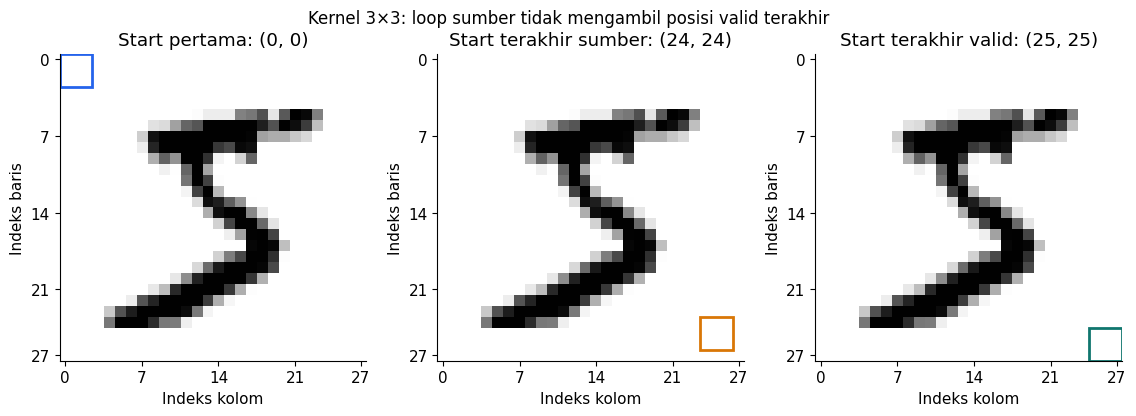

In [ ]:
# Grafik 4: posisi terakhir yang digunakan sumber dan valid standar.
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4))
titles = ['Start pertama: (0, 0)', 'Start terakhir sumber: (24, 24)',
          'Start terakhir valid: (25, 25)']
for ax, (r, c), title, color in zip(axes, [(0, 0), (24, 24), (25, 25)], titles,
                                   ['#2563eb', '#d97706', '#0f766e']):
    ax.imshow(demo_batch[0], cmap='gray_r', vmin=0, vmax=1)
    ax.add_patch(Rectangle((c-0.5, r-0.5), 3, 3, fill=False, edgecolor=color, linewidth=2))
    ax.set(title=title, xticks=[0, 7, 14, 21, 27], yticks=[0, 7, 14, 21, 27],
           xlabel='Indeks kolom', ylabel='Indeks baris')
fig.suptitle('Kernel 3×3: loop sumber tidak mengambil posisi valid terakhir', fontsize=12)
fig.tight_layout()
plt.show()

## 10. Jumlah parameter: tentukan pembanding yang setara

Pada geometri sumber: 25 × 25 posisi, 16 kernel, dan 10.000 hidden activation. Convolution hanya mempunyai **144 bobot**, tetapi classifier dense mempunyai **100.000 bobot**. Totalnya **100.144**, tanpa bias.

| Model/pembanding | Bobot ekstraksi feature | Bobot classifier | Total |
| --- | --- | --- | --- |
| CNN listing Chapter 10 | $3\times3\times16=144$ | $10.000\times10=100.000$ | 100.144 |
| Local layer tanpa sharing, output 25×25×16 sama | $625\times9\times16=90.000$ | 100.000 | 190.000 |
| Dense 784 ke 10.000 hidden, output sama | $784\times10.000=7.840.000$ | 100.000 | 7.940.000 |
| Dense Chapter 9, hidden size 100 | $784\times100=78.400$ | $100\times10=1.000$ | 79.400 |

Weight sharing mengurangi bobot feature layer **625 kali** dibandingkan local layer yang tidak berbagi kernel dengan geometri sama. Namun CNN lengkap pada listing ini memiliki lebih banyak total parameter daripada jaringan kecil Chapter 9, karena flatten menghasilkan classifier yang jauh lebih besar. Jadi jangan menyimpulkan model lengkap selalu lebih kecil hanya karena convolution memakai sedikit bobot.

Mengubah ke valid 26 × 26 memberi 10.816 hidden activation dan membutuhkan ukuran head yang berbeda. Itu perubahan arsitektur, sehingga tidak dilakukan pada trainer pembanding yang menjaga geometri sumber.

**Rujukan:** Trask (2019), hlm. 178-184; hitungan serta pembanding di atas dihitung dari konfigurasi sumber.

In [ ]:
# Pemeriksaan jumlah parameter dan memori tensor sumber.
source_positions, source_hidden_size = 25*25, 25*25*16
source_kernel_parameters = 3*3*16
source_head_parameters = source_hidden_size*10
source_total_parameters = source_kernel_parameters+source_head_parameters
untied_local_parameters = source_positions*3*3*16
print('Convolution:', source_kernel_parameters, '; head:', source_head_parameters,
      '; total:', source_total_parameters)
print('Local tanpa sharing:', untied_local_parameters, '; rasio sharing:',
      untied_local_parameters/source_kernel_parameters)
print('Patch batch 128:', 128*625*9*8/1e6, 'MB float64')
print('Hidden batch 128:', 128*10000*8/1e6, 'MB float64')
print('Hidden valid 26×26:', 26*26*16, '; bobot head:', 26*26*16*10)
assert source_total_parameters == 100144
assert untied_local_parameters/source_kernel_parameters == 625

Convolution: 144 ; head: 100000 ; total: 100144
Local tanpa sharing: 90000 ; rasio sharing: 625.0
Patch batch 128: 5.76 MB float64
Hidden batch 128: 10.24 MB float64
Hidden valid 26×26: 10816 ; bobot head: 108160


## 11. Translation equivariance dan batas invariance

Weight sharing membuat convolution pada area yang sesuai merespons pergeseran input dengan pergeseran feature map yang sama. Sifat ini disebut **translation equivariance**. Batas gambar, padding, stride, atau crop dapat mengubah hubungan tersebut.

Equivariance tidak sama dengan invariance. Invariance berarti output tidak berubah saat input bergeser. Feature map convolution justru biasanya ikut bergeser. Flatten dan dense head sumber memakai bobot berbeda pada posisi berbeda, sehingga keseluruhan classifier tidak dijamin invariant terhadap pergeseran.

Demonstrasi berikut memeriksa equivariance untuk pergeseran satu pixel ke kanan, stride satu, padding nol satu pixel, pada area output yang saling sesuai. Tidak ada penggulungan pixel dari sisi kanan ke kiri seperti pada `np.roll`.

**Rujukan:** Trask (2019), hlm. 178-180, untuk detektor yang dipakai di banyak lokasi; pembedaan matematis berikut adalah pendalaman.

In [ ]:
# Pendalaman: respons bergeser pada area yang sama, bukan berubah menjadi invariant.
def same_correlation_demo(image, kernel_bank):
    padded = np.pad(image[None], ((0, 0), (1, 1), (1, 1)))
    patches = extract_patches(padded, source_geometry=False)
    F = kernel_bank.shape[2]
    return (patches.reshape(-1, 9) @ kernel_bank.reshape(9, F)).reshape(8, 8, F)

shifted_digit = np.zeros_like(toy_digit)
shifted_digit[:, 1:] = toy_digit[:, :-1]
original_response = same_correlation_demo(toy_digit, demo_kernels)
shifted_response = same_correlation_demo(shifted_digit, demo_kernels)
equivariance_error = float(np.max(np.abs(shifted_response[:, 1:] - original_response[:, :-1])))
assert np.allclose(shifted_response[:, 1:], original_response[:, :-1])
assert not np.array_equal(original_response, shifted_response)
print('Maksimum selisih pada area output yang digeser:', equivariance_error)
print('Feature map ikut bergeser; nilainya bukan invariant pada lokasi tetap.')

Maksimum selisih pada area output yang digeser: 0.0
Feature map ikut bergeser; nilainya bukan invariant pada lokasi tetap.


## 12. Forward dan backward untuk shared kernel

Misalkan $A$ adalah matriks patch $(BP)\times9$, $K$ adalah kernel bank $9\times16$, dan $W$ adalah bobot classifier $(P\cdot16)\times10$:

$$U=AK,\qquad H=\tanh(\operatorname{reshape}(U)),\qquad
\widetilde H=H\odot M/q,\qquad Z_2=\widetilde HW,\qquad P_2=\operatorname{softmax}(Z_2).$$

Dengan mean categorical cross-entropy $L=-\frac1B\sum_b\sum_cY_{bc}\log P_{2,bc}$:

$$D_2=(P_2-Y)/B,\qquad
D_1=(D_2W^{\mathsf T})\odot(M/q)\odot(1-H^2).$$

Gradien classifier dan kernel adalah:

$$\nabla_WL=\widetilde H^{\mathsf T}D_2,\qquad
\nabla_KL=A^{\mathsf T}\operatorname{reshape}(D_1).$$

Perkalian terakhir menjumlahkan kontribusi semua sampel dan **semua posisi** tempat kernel dipakai. Tidak ada pembagian tambahan oleh jumlah patch, sebab loss didefinisikan sebagai rata-rata atas gambar, bukan rata-rata prediksi patch terpisah. Gradien kernel dapat ditulis:

$$\frac{\partial L}{\partial K_{u,v,f}}=
\sum_{b,r,c}X_{b,r+u,c+v}\frac{\partial L}{\partial U_{b,r,c,f}}.$$

Jika perlu melatih layer sebelum convolution, gradien input dapat dihitung dari gradien patch lalu dijumlahkan pada pixel yang overlap (**col2im/scatter-add**). Pada layer pertama sumber, pixel adalah data tetap sehingga backward sampai kernel sudah cukup untuk update parameter.

Semua gradien perlu dihitung dari keadaan bobot yang sama sebelum update. Pendalaman menggunakan konvensi descent $W\leftarrow W-\alpha\nabla_WL$ dan $K\leftarrow K-\alpha\nabla_KL$.

**Rujukan:** Trask (2019), hlm. 181-184; derivasi dengan mean cross-entropy dan cache eksplisit merupakan pendalaman.

In [ ]:
# Fungsi aktivasi sumber, halaman 182.
def tanh(x):
    return np.tanh(x)

def tanh2deriv(output):
    return 1-(output**2)

def softmax(x):
    temp = np.exp(x)
    return temp/np.sum(temp, axis=1, keepdims=True)

# Tambahan stabil untuk evaluasi/pendalaman.
def softmax_stable(logits):
    shifted = logits-np.max(logits, axis=1, keepdims=True)
    exponentials = np.exp(shifted)
    return exponentials/exponentials.sum(axis=1, keepdims=True)

def log_softmax_stable(logits):
    shifted = logits-np.max(logits, axis=1, keepdims=True)
    return shifted-np.log(np.exp(shifted).sum(axis=1, keepdims=True))

def cnn_loss_and_gradients(patches, targets, kernel_bank, head, mask, keep_probability=0.5):
    B, P, kernel_elements = patches.shape
    F = kernel_bank.shape[1]
    A = patches.reshape(B*P, kernel_elements)
    hidden = tanh((A @ kernel_bank).reshape(B, P*F))
    multiplier = mask/keep_probability
    hidden_dropout = hidden*multiplier
    logits = hidden_dropout @ head
    probabilities = softmax_stable(logits)
    loss = float(-np.mean(np.sum(targets*log_softmax_stable(logits), axis=1)))
    D2 = (probabilities-targets)/B
    D1 = (D2 @ head.T)*multiplier*tanh2deriv(hidden)
    head_gradient = hidden_dropout.T @ D2
    kernel_gradient = A.T @ D1.reshape(B*P, F)
    return loss, kernel_gradient, head_gradient, probabilities, D1

## 13. Pemeriksaan numerik semua parameter pada CNN kecil

Contoh kecil memakai dua gambar 4 × 4, dua kernel 2 × 2, valid map 3 × 3, serta tiga kelas. Ada delapan bobot kernel dan 54 bobot classifier, jadi **62 parameter** diperiksa dengan finite difference.

Mask dropout dibuat sekali dan tetap sama saat menghitung loss dengan bobot plus/minus. Jika mask berubah, selisih loss mencampur efek random dengan perubahan parameter. Verifikasi ini menguji gradient mean cross-entropy sesuai definisi forward, bukan sekadar apakah accuracy training meningkat.

Gradien batch juga diperiksa terhadap rata-rata gradien per sampel, dan gradien kernel terhadap jumlah kontribusi seluruh posisi. Hal tersebut menguji normalisasi batch serta penggunaan parameter yang sama di banyak lokasi.

In [ ]:
# Pendalaman finite difference: periksa seluruh 62 parameter CNN kecil.
toy_cnn_rng = np.random.RandomState(19)
toy_cnn_images = toy_cnn_rng.uniform(0, 1, (2, 4, 4))
toy_cnn_patches = extract_patches(toy_cnn_images, 2, 2, source_geometry=False)
toy_cnn_targets = np.eye(3)[[0, 2]]
toy_cnn_K = toy_cnn_rng.uniform(-0.3, 0.3, (4, 2))
toy_cnn_W = toy_cnn_rng.uniform(-0.3, 0.3, (18, 3))
toy_cnn_mask = toy_cnn_rng.randint(2, size=(2, 18))
epsilon = 1e-6
toy_loss, toy_GK, toy_GW, toy_probs, toy_D1 = cnn_loss_and_gradients(
    toy_cnn_patches, toy_cnn_targets, toy_cnn_K, toy_cnn_W, toy_cnn_mask)

numeric_gradients = []
for which, parameter, analytic in [(0, toy_cnn_K, toy_GK), (1, toy_cnn_W, toy_GW)]:
    numerical = np.zeros_like(parameter)
    for index in np.ndindex(parameter.shape):
        plus, minus = parameter.copy(), parameter.copy()
        plus[index] += epsilon
        minus[index] -= epsilon
        if which == 0:
            loss_plus = cnn_loss_and_gradients(toy_cnn_patches, toy_cnn_targets, plus, toy_cnn_W, toy_cnn_mask)[0]
            loss_minus = cnn_loss_and_gradients(toy_cnn_patches, toy_cnn_targets, minus, toy_cnn_W, toy_cnn_mask)[0]
        else:
            loss_plus = cnn_loss_and_gradients(toy_cnn_patches, toy_cnn_targets, toy_cnn_K, plus, toy_cnn_mask)[0]
            loss_minus = cnn_loss_and_gradients(toy_cnn_patches, toy_cnn_targets, toy_cnn_K, minus, toy_cnn_mask)[0]
        numerical[index] = (loss_plus-loss_minus)/(2*epsilon)
    assert np.allclose(numerical, analytic, atol=1e-8, rtol=1e-6)
    numeric_gradients.append(numerical)

cnn_gradient_max_error = float(max(np.max(np.abs(numeric_gradients[0]-toy_GK)),
                                 np.max(np.abs(numeric_gradients[1]-toy_GW))))
sample_gradients = [cnn_loss_and_gradients(toy_cnn_patches[n:n+1], toy_cnn_targets[n:n+1],
                                         toy_cnn_K, toy_cnn_W, toy_cnn_mask[n:n+1])
                    for n in range(2)]
assert np.allclose(np.mean([r[1] for r in sample_gradients], axis=0), toy_GK)
assert np.allclose(np.mean([r[2] for r in sample_gradients], axis=0), toy_GW)
position_delta = toy_D1.reshape(2, 9, 2)
kernel_contributions = [toy_cnn_patches[:, p, :].T @ position_delta[:, p, :] for p in range(9)]
assert np.allclose(np.sum(kernel_contributions, axis=0), toy_GK)
print('Parameter diperiksa:', toy_cnn_K.size+toy_cnn_W.size)
print('Maksimum selisih gradien:', format(cnn_gradient_max_error, '.3e'))
print('Gradien batch = mean gradien sampel; gradien kernel = sum kontribusi semua posisi: sesuai.')

Parameter diperiksa: 62
Maksimum selisih gradien: 1.939e-10
Gradien batch = mean gradien sampel; gradien kernel = sum kontribusi semua posisi: sesuai.


## 14. Catatan implementasi listing sumber

| Detail sumber | Perilaku | Catatan matematis |
| --- | --- | --- |
| `range(H-kernel_rows)` | 25 × 25 posisi pada MNIST | Valid standar memerlukan `+1`; reproduksi mempertahankan 25 × 25 |
| `int(1000/128)` | 896 gambar diperbarui; 104 dilewati | Accuracy online sumber tetap dibagi 1.000 |
| `layer_1 *= dropout_mask * 2` | Cache tanh asli diganti hasil dropout | Turunan tanh perlu hasil sebelum dropout |
| `tanh2deriv(layer_1)` setelah scaling | Menghitung $1-\widetilde H^2$ | Bisa negatif; tidak sama dengan $1-H^2$ |
| Backward `*= dropout_mask` | Hanya multiplier $M$ | Forward $M/q$ memerlukan backward $M/q$ pula |
| Delta dibagi `batch_size * layer_2.shape[0]` | Pembagi $B^2$ | Mean CE memakai pembagi $B$ sekali |
| `weights_1_2 +=`, tetapi `kernels -=` | Dua tanda update untuk konvensi delta target-prediksi yang sama | Arah kernel berlawanan dari aturan descent yang konsisten |

Untuk memisahkan masalah tanda dari dropout/cache, contoh berikut mematikan dropout. Dengan arah delta positif $(Y-P)/B^2$, perkalian matriks source menghasilkan **negatif** dari gradien loss mean, dikalikan faktor $1/B$. Update head `+=` bergerak ke arah descent. Update kernel `-=` justru bergerak ke arah gradien positif dalam kondisi tersebut.

Pada run sumber dengan dropout, cache yang berubah menambahkan perbedaan lain, sehingga seluruh dinamika tidak dapat dijelaskan hanya dari satu tanda. Reproduksi tetap memakai tanda, cache, serta skala asli agar hasilnya dapat ditelusuri.

**Rujukan:** Trask (2019), hlm. 181-184; penjelasan tanda dibuktikan dengan contoh berikut.

In [ ]:
# Diagnostik tanda: dropout dimatikan untuk mengisolasi arah update source.
no_dropout_mask = np.ones((2, 18))
sign_loss, sign_GK, sign_GW, sign_probs, _ = cnn_loss_and_gradients(
    toy_cnn_patches, toy_cnn_targets, toy_cnn_K, toy_cnn_W, no_dropout_mask, 1.0)
sign_A = toy_cnn_patches.reshape(-1, 4)
sign_H = tanh((sign_A @ toy_cnn_K).reshape(2, 18))
source_positive_D2 = (toy_cnn_targets-sign_probs)/(2*2)
source_positive_D1 = (source_positive_D2 @ toy_cnn_W.T)*tanh2deriv(sign_H)
source_head_direction = sign_H.T @ source_positive_D2
source_kernel_direction = -(sign_A.T @ source_positive_D1.reshape(-1, 2))
assert np.allclose(2*source_head_direction, -sign_GW)
assert np.allclose(2*source_kernel_direction, sign_GK)
step = 1e-4
kernel_wrong_loss = cnn_loss_and_gradients(
    toy_cnn_patches, toy_cnn_targets, toy_cnn_K+step*source_kernel_direction,
    toy_cnn_W, no_dropout_mask, 1.0)[0]
kernel_descent_loss = cnn_loss_and_gradients(
    toy_cnn_patches, toy_cnn_targets, toy_cnn_K-step*sign_GK,
    toy_cnn_W, no_dropout_mask, 1.0)[0]
assert kernel_wrong_loss > sign_loss > kernel_descent_loss
print('Loss sebelum perubahan:', sign_loss)
print('Satu langkah kecil arah kernel source:', kernel_wrong_loss)
print('Satu langkah kecil gradient descent kernel:', kernel_descent_loss)
print('Tanpa dropout, arah head source sesuai descent; arah kernel source berlawanan.')

Loss sebelum perubahan: 1.0980849020234849
Satu langkah kecil arah kernel source: 1.0980886536468162
Satu langkah kecil gradient descent kernel: 1.098077398827056
Tanpa dropout, arah head source sesuai descent; arah kernel source berlawanan.


## 15. Evaluasi inference tanpa dropout

Pada inference, seluruh activation tanh digunakan tanpa mask dan tanpa faktor dua. Buku menghitung kelas dari logit linear. Karena softmax mempertahankan urutan logit, argmax logit sama dengan argmax probabilitas softmax.

Evaluator tambahan menghitung accuracy dan mean categorical cross-entropy pada satu keadaan bobot tetap. Split laporan meliputi semua 1.000 gambar terpilih, 896 gambar yang diperbarui, 104 gambar yang dilewati, validation tambahan, dan test. Data yang dilewati membantu membaca konsekuensi batch truncation; validation tambahan tetap terpisah dari seluruh 1.000 gambar terpilih.

Evaluator memproses 128 gambar per chunk. Patch vectorized sudah diperiksa terhadap ekstraksi sumber. Loss tambahan dihitung stabil dari logit, tidak dipakai untuk mengubah update reproduksi atau memilih checkpoint. Pencetakan dan evaluasi dilakukan pada indeks epoch 0-8, kelipatan sepuluh, serta 297-299. Tidak ada epoch training yang dilewati.

In [ ]:
# Evaluasi tambahan pada geometri sumber; chunk mengendalikan penggunaan memori.
def cnn_inference_logits(flat_images, kernel_bank, head, chunk_size=128):
    chunks = []
    for start in range(0, len(flat_images), chunk_size):
        Xb = flat_images[start:start+chunk_size].reshape(-1, 28, 28)
        patches = extract_patches(Xb)
        hidden = tanh((patches.reshape(-1, 9) @ kernel_bank).reshape(len(Xb), -1))
        chunks.append(hidden @ head)
    return np.concatenate(chunks, axis=0)

def evaluate_cnn(X, Y, kernel_bank, head):
    logits = cnn_inference_logits(X, kernel_bank, head)
    correct = int(np.sum(logits.argmax(axis=1) == Y.argmax(axis=1)))
    loss = float(-np.mean(np.sum(Y*log_softmax_stable(logits), axis=1)))
    return {'accuracy': correct/len(X), 'cross_entropy': loss, 'correct': correct}

def collect_cnn_metrics(kernel_bank, head):
    # Train digunakan/dilewati diambil dari hasil semua train untuk menghindari forward berulang.
    train_logits = cnn_inference_logits(images, kernel_bank, head)
    train_log_probs = log_softmax_stable(train_logits)
    correct = train_logits.argmax(axis=1) == labels.argmax(axis=1)
    losses = -np.sum(labels*train_log_probs, axis=1)
    metrics = {}
    for name, selection in [('train_all', slice(None)), ('train_used', slice(0, 896)),
                             ('train_unused', slice(896, None))]:
        metrics[name] = {'accuracy': float(correct[selection].mean()),
                         'cross_entropy': float(losses[selection].mean()),
                         'correct': int(correct[selection].sum())}
    metrics['validation'] = evaluate_cnn(validation_images, validation_labels, kernel_bank, head)
    metrics['test'] = evaluate_cnn(test_images, test_labels, kernel_bank, head)
    return metrics

def source_inference_loop(kernel_bank, head):
    # Loop satu gambar dengan ekstraksi patch sumber, hlm. 183-184.
    test_correct_cnt = 0
    for i in range(len(test_images)):
        layer_0 = test_images[i:i+1]
        layer_0 = layer_0.reshape(layer_0.shape[0], 28, 28)
        expanded_input = source_expand_patches(layer_0)
        es = expanded_input.shape
        flattened_input = expanded_input.reshape(es[0]*es[1], -1)
        kernel_output = flattened_input.dot(kernel_bank)
        layer_1 = tanh(kernel_output.reshape(es[0], -1))
        layer_2 = np.dot(layer_1, head)
        test_correct_cnt += int(np.argmax(layer_2) == np.argmax(test_labels[i:i+1]))
    return test_correct_cnt

## 16. Reproduksi CNN MNIST: 300 epoch penuh

Sel berikut mereproduksi forward, RNG, dropout, dan update sumber. Termasuk perilaku source: map 25 × 25, tujuh batch per epoch, delta positif dibagi $128^2$, cache tanh setelah dropout, mask backward tanpa faktor dua, dan tanda kernel `-=`.

Timer, history, assertions untuk shape/finite, serta hitungan update merupakan tambahan. Evaluasi test dialihkan ke matriks pada checkpoint untuk efisiensi. Karena inference tidak memakai mask atau RNG, adaptasi ini tidak mengubah angka random yang digunakan pada training.

Tidak ada bias, shuffle, padding, atau pooling. `I:0` berarti epoch pertama telah selesai; `I:299` berarti seluruh 300 epoch sudah dijalankan. Accuracy online yang dicetak memakai denominator 1.000 sesuai sumber, dengan nilai per 896 gambar disediakan sebagai pembanding.

**Rujukan:** Trask (2019), hlm. 182-184; listing dicocokkan dengan [notebook resmi penulis](https://github.com/iamtrask/Grokking-Deep-Learning/blob/master/Chapter10%20-%20Intro%20to%20Convolutional%20Neural%20Networks%20-%20Learning%20Edges%20and%20Corners.ipynb).

In [ ]:
# Reproduksi training sumber, termasuk tanda dan cache yang dijelaskan sebelumnya.
np.random.seed(1)
alpha, iterations = (2, 300)
pixels_per_image, num_labels = (784, 10)
batch_size = 128
input_rows, input_cols = 28, 28
kernel_rows, kernel_cols, num_kernels = 3, 3, 16
hidden_size = ((input_rows-kernel_rows)*(input_cols-kernel_cols))*num_kernels
kernels = 0.02*np.random.random((kernel_rows*kernel_cols, num_kernels))-0.01
weights_1_2 = 0.2*np.random.random((hidden_size, num_labels))-0.1
book_initial_K, book_initial_W = kernels.copy(), weights_1_2.copy()

book_history, book_online_history = [], []
book_updates, book_training_seconds = 0, 0.0
for j in range(iterations):
    epoch_started = time.perf_counter()
    correct_cnt = 0
    for i in range(int(len(images)/batch_size)):
        batch_start, batch_end = ((i*batch_size), ((i+1)*batch_size))
        layer_0 = images[batch_start:batch_end]
        layer_0 = layer_0.reshape(layer_0.shape[0], 28, 28)
        sects = list()
        for row_start in range(layer_0.shape[1]-kernel_rows):
            for col_start in range(layer_0.shape[2]-kernel_cols):
                sect = get_image_section(layer_0, row_start, row_start+kernel_rows,
                                         col_start, col_start+kernel_cols)
                sects.append(sect)
        expanded_input = np.concatenate(sects, axis=1)
        es = expanded_input.shape
        flattened_input = expanded_input.reshape(es[0]*es[1], -1)
        kernel_output = flattened_input.dot(kernels)
        layer_1 = tanh(kernel_output.reshape(es[0], -1))
        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask*2
        layer_2 = softmax(np.dot(layer_1, weights_1_2))

        for k in range(batch_size):
            labelset = labels[batch_start+k:batch_start+k+1]
            _inc = int(np.argmax(layer_2[k:k+1]) == np.argmax(labelset))
            correct_cnt += _inc

        layer_2_delta = (labels[batch_start:batch_end]-layer_2)/(batch_size*layer_2.shape[0])
        layer_1_delta = layer_2_delta.dot(weights_1_2.T)*tanh2deriv(layer_1)
        layer_1_delta *= dropout_mask
        weights_1_2 += alpha*layer_1.T.dot(layer_2_delta)
        l1d_reshape = layer_1_delta.reshape(kernel_output.shape)
        k_update = flattened_input.T.dot(l1d_reshape)
        kernels -= alpha*k_update

        book_updates += 1
        assert flattened_input.shape == (128*625, 9)
        assert layer_1.shape == (128, 10000)
        assert np.isfinite(layer_2).all() and np.allclose(layer_2.sum(axis=1), 1)

    book_training_seconds += time.perf_counter()-epoch_started
    book_online_history.append({'index': j, 'correct_count': correct_cnt,
                                 'source_online_accuracy': correct_cnt/len(images),
                                 'used_online_accuracy': correct_cnt/used_count})
    if j < 9 or j % 10 == 0 or j >= 297:
        metrics = collect_cnn_metrics(kernels, weights_1_2)
        book_history.append({'index': j, 'epoch': j+1,
                             'source_online_accuracy': correct_cnt/len(images),
                             'used_online_accuracy': correct_cnt/used_count, **metrics})
        print(f'I:{j:3d} Test-Acc:{metrics["test"]["accuracy"]:.4f} '
              f'Train-Acc-source:{correct_cnt/len(images):.3f} '
              f'Train-Acc-online/896:{correct_cnt/used_count:.3f} '
              f'Train-inference/896:{metrics["train_used"]["accuracy"]:.3f}')

book_K, book_W = kernels.copy(), weights_1_2.copy()
book_final = book_history[-1]
assert book_updates == iterations*7 == 2100
assert len(book_online_history) == 300 and book_history[-1]['index'] == 299
assert np.isfinite(book_K).all() and np.isfinite(book_W).all()
print('Epoch penuh:', iterations, '; update:', book_updates, '; gambar/epoch:', used_count)
print('Waktu loop training di luar evaluasi:', round(book_training_seconds, 2), 'detik')

I:  0 Test-Acc:0.0288 Train-Acc-source:0.055 Train-Acc-online/896:0.061 Train-inference/896:0.022
I:  1 Test-Acc:0.0273 Train-Acc-source:0.037 Train-Acc-online/896:0.041 Train-inference/896:0.018
I:  2 Test-Acc:0.0280 Train-Acc-source:0.037 Train-Acc-online/896:0.041 Train-inference/896:0.021
I:  3 Test-Acc:0.0292 Train-Acc-source:0.040 Train-Acc-online/896:0.045 Train-inference/896:0.029
I:  4 Test-Acc:0.0339 Train-Acc-source:0.046 Train-Acc-online/896:0.051 Train-inference/896:0.031
I:  5 Test-Acc:0.0478 Train-Acc-source:0.068 Train-Acc-online/896:0.076 Train-inference/896:0.039
I:  6 Test-Acc:0.0760 Train-Acc-source:0.083 Train-Acc-online/896:0.093 Train-inference/896:0.069
I:  7 Test-Acc:0.1316 Train-Acc-source:0.096 Train-Acc-online/896:0.107 Train-inference/896:0.127
I:  8 Test-Acc:0.2137 Train-Acc-source:0.127 Train-Acc-online/896:0.142 Train-inference/896:0.215
I: 10 Test-Acc:0.3563 Train-Acc-source:0.181 Train-Acc-online/896:0.202 Train-inference/896:0.334
I: 20 Test-Acc:0.013

## 17. Membandingkan dengan checkpoint sumber

Angka berikut berasal dari tabel hlm. 184, yaitu sembilan epoch awal dan tiga epoch terakhir. Angka pembanding disertakan untuk verifikasi; output training sendiri dihasilkan dari eksekusi sel sebelumnya.

Notebook melaporkan selisih terhadap angka tersebut. Toleransi accuracy $10^{-4}$ setara dengan satu gambar test; akumulasi floating point dapat berbeda antar-NumPy/BLAS. Selain membandingkan angka buku, loop source satu gambar pada seluruh 10.000 test diperiksa terhadap evaluator matriks pada bobot akhir.

Bagian awal source sangat tidak stabil. Mengetahui listing berbeda dari gradien loss standar membantu membaca kurva tersebut, tetapi tidak membuktikan bahwa satu masalah kode saja menyebabkan seluruh pola dinamika training.

In [ ]:
# Pembanding dari halaman 184; tidak dipakai sebagai output training buatan.
expected_test = {0: 0.0288, 1: 0.0273, 2: 0.0280, 3: 0.0292, 4: 0.0339,
                 5: 0.0478, 6: 0.0760, 7: 0.1316, 8: 0.2137,
                 297: 0.8774, 298: 0.8774, 299: 0.8774}
expected_online = {0: 0.055, 1: 0.037, 2: 0.037, 3: 0.040, 4: 0.046,
                   5: 0.068, 6: 0.083, 7: 0.096, 8: 0.127,
                   297: 0.816, 298: 0.804, 299: 0.814}
book_by_index = {row['index']: row for row in book_history}
checkpoint_test_max_gap = max(abs(book_by_index[index]['test']['accuracy']-value)
                              for index, value in expected_test.items())
checkpoint_online_max_gap = max(abs(book_by_index[index]['source_online_accuracy']-value)
                                for index, value in expected_online.items())
reference_checkpoints_match = (checkpoint_test_max_gap <= 0.0001+1e-12 and
                               checkpoint_online_max_gap <= 0.001+1e-12)
for index, expected in expected_test.items():
    print(f'I:{index:3d}: test aktual={book_by_index[index]["test"]["accuracy"]:.4f}, '
          f'tabel sumber={expected:.4f}')
print('Maksimum selisih test:', checkpoint_test_max_gap)
print('Maksimum selisih online source:', checkpoint_online_max_gap)
print('Checkpoint sesuai dalam toleransi yang dinyatakan?', reference_checkpoints_match)

source_loop_correct = source_inference_loop(book_K, book_W)
assert source_loop_correct == book_final['test']['correct']
print('Loop test source:', source_loop_correct, '/', len(test_images))
print('Evaluator matriks:', book_final['test']['correct'], '/', len(test_images))
print('Accuracy online terakhir source:', book_online_history[-1]['source_online_accuracy'])
print('Accuracy online terakhir per 896 gambar:', book_online_history[-1]['used_online_accuracy'])

I:  0: test aktual=0.0288, tabel sumber=0.0288
I:  1: test aktual=0.0273, tabel sumber=0.0273
I:  2: test aktual=0.0280, tabel sumber=0.0280
I:  3: test aktual=0.0292, tabel sumber=0.0292
I:  4: test aktual=0.0339, tabel sumber=0.0339
I:  5: test aktual=0.0478, tabel sumber=0.0478
I:  6: test aktual=0.0760, tabel sumber=0.0760
I:  7: test aktual=0.1316, tabel sumber=0.1316
I:  8: test aktual=0.2137, tabel sumber=0.2137
I:297: test aktual=0.8774, tabel sumber=0.8774
I:298: test aktual=0.8774, tabel sumber=0.8774
I:299: test aktual=0.8774, tabel sumber=0.8774
Maksimum selisih test: 0.0
Maksimum selisih online source: 0.0
Checkpoint sesuai dalam toleransi yang dinyatakan? True
Loop test source: 8774 / 10000
Evaluator matriks: 8774 / 10000
Accuracy online terakhir source: 0.814
Accuracy online terakhir per 896 gambar: 0.9084821428571429


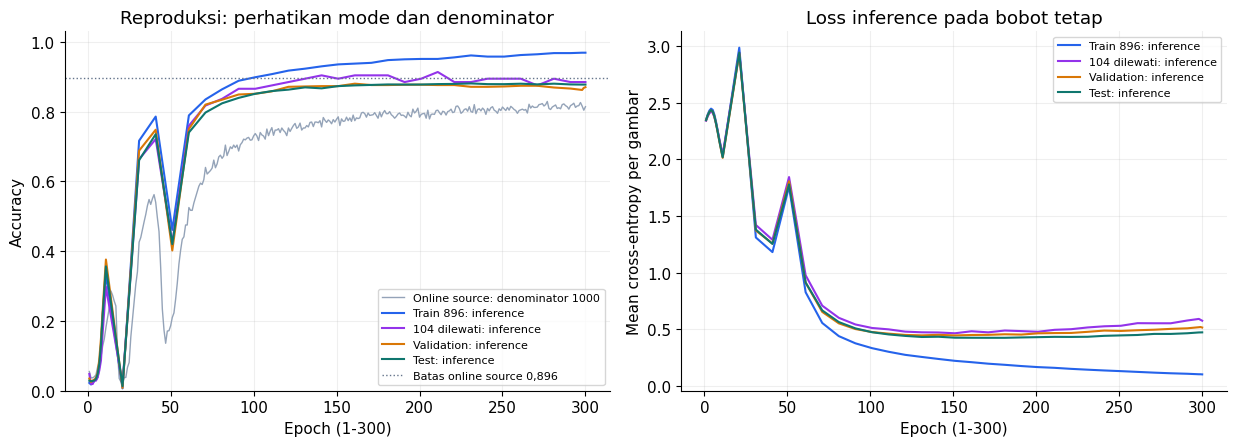

In [ ]:
# Grafik 5: accuracy dalam mode berbeda dan mean cross-entropy tambahan.
epochs = [row['epoch'] for row in book_history]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].plot(np.arange(1, 301), [r['source_online_accuracy'] for r in book_online_history],
             color='#94a3b8', linewidth=1, label='Online source: denominator 1000')
colors = {'train_used': '#2563eb', 'train_unused': '#9333ea',
          'validation': '#d97706', 'test': '#0f766e'}
names = {'train_used': 'Train 896: inference', 'train_unused': '104 dilewati: inference',
         'validation': 'Validation: inference', 'test': 'Test: inference'}
for split, color in colors.items():
    axes[0].plot(epochs, [row[split]['accuracy'] for row in book_history], color=color, label=names[split])
    axes[1].plot(epochs, [row[split]['cross_entropy'] for row in book_history], color=color, label=names[split])
axes[0].axhline(0.896, color='#64748b', linestyle=':', linewidth=1,
                label='Batas online source 0,896')
axes[0].set(title='Reproduksi: perhatikan mode dan denominator', xlabel='Epoch (1-300)',
            ylabel='Accuracy', ylim=(0, 1.03))
axes[1].set(title='Loss inference pada bobot tetap', xlabel='Epoch (1-300)',
            ylabel='Mean cross-entropy per gambar')
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 18. Pendalaman: training dengan gradien konsisten

Trainer tambahan mempertahankan geometri 25 × 25, 16 kernel, head 10.000 × 10, 896 sampel, urutan tujuh batch, seed 1, bobot awal, dropout 50%, dan 300 epoch. Perubahan meliputi cache tanh sebelum dropout, backward $M/q$, mean CE dengan pembagian batch sekali, stable softmax, dan tanda descent yang konsisten untuk kernel maupun head.

Learning rate ditetapkan **$2/128=0{,}015625$** sebelum membaca hasil test. Skala ini menyamakan faktor update head awal: sumber memakai alpha 2 dengan pembagi $B^2$, sedangkan pendalaman memakai pembagi $B$. Gradien kernel/hidden berubah sesuai aturan rantai, sehingga lintasan bobot setelah update tidak lagi sama.

Patch 896 gambar dapat disiapkan sekali untuk trainer tambahan karena input tidak berubah. Cache sekitar 40,32 MB ini mengurangi pengulangan ekstraksi. Reproduksi sebelumnya tetap membuat patch dalam loop seperti listing. Perbedaan caching membuat waktu kedua program tidak layak dibaca sebagai benchmark algoritma semata.

Ini bukan eksperimen yang sekaligus mengubah geometri ke valid standar, memasukkan 104 gambar yang terlewat, atau menambah pooling. Pilihan tersebut mengubah arsitektur/data dan perlu eksperimen tersendiri. Koreksi matematis tidak menjamin test accuracy lebih tinggi; hasil yang benar-benar diperoleh dilaporkan apa adanya.

In [ ]:
# Pendalaman 300 epoch pada geometri dan data yang sama dengan source.
corrected_rng = np.random.RandomState(1)
corrected_K = 0.02*corrected_rng.random_sample((9, 16))-0.01
corrected_W = 0.2*corrected_rng.random_sample((10000, 10))-0.1
assert np.array_equal(corrected_K, book_initial_K)
assert np.array_equal(corrected_W, book_initial_W)
corrected_alpha, corrected_iterations, corrected_batch_size = 2/128, 300, 128
training_patch_cache = extract_patches(used_images.reshape(-1, 28, 28))
assert training_patch_cache.shape == (896, 625, 9)
corrected_history, corrected_online_history = [], []
corrected_updates, corrected_training_seconds = 0, 0.0

for j in range(corrected_iterations):
    epoch_started = time.perf_counter()
    online_correct = 0
    for start in range(0, used_count, corrected_batch_size):
        patches = training_patch_cache[start:start+corrected_batch_size]
        Yb = used_labels[start:start+corrected_batch_size]
        mask = corrected_rng.randint(2, size=(len(patches), 10000))
        loss, GK, GW, probabilities, _ = cnn_loss_and_gradients(
            patches, Yb, corrected_K, corrected_W, mask)
        online_correct += int(np.sum(probabilities.argmax(axis=1) == Yb.argmax(axis=1)))
        corrected_W -= corrected_alpha*GW
        corrected_K -= corrected_alpha*GK
        corrected_updates += 1
        assert np.isfinite(loss)
    corrected_training_seconds += time.perf_counter()-epoch_started
    corrected_online_history.append({'index': j, 'online_accuracy': online_correct/used_count})
    if j < 9 or j % 10 == 0 or j >= 297:
        metrics = collect_cnn_metrics(corrected_K, corrected_W)
        corrected_history.append({'index': j, 'epoch': j+1,
                                  'used_online_accuracy': online_correct/used_count, **metrics})
        print(f'I:{j:3d} Test-Acc:{metrics["test"]["accuracy"]:.4f} '
              f'Train-Acc-online/896:{online_correct/used_count:.3f} '
              f'Train-inference/896:{metrics["train_used"]["accuracy"]:.3f}')

corrected_final = corrected_history[-1]
assert corrected_updates == 2100 and len(corrected_online_history) == 300
assert np.isfinite(corrected_K).all() and np.isfinite(corrected_W).all()
print('Epoch tambahan:', corrected_iterations, '; update:', corrected_updates)
print('Cache patch:', training_patch_cache.nbytes/1e6, 'MB')
print('Waktu training di luar evaluasi dan persiapan cache:', round(corrected_training_seconds, 2), 'detik')

I:  0 Test-Acc:0.2504 Train-Acc-online/896:0.170 Train-inference/896:0.292
I:  1 Test-Acc:0.3207 Train-Acc-online/896:0.217 Train-inference/896:0.345
I:  2 Test-Acc:0.3751 Train-Acc-online/896:0.242 Train-inference/896:0.403
I:  3 Test-Acc:0.4166 Train-Acc-online/896:0.277 Train-inference/896:0.461
I:  4 Test-Acc:0.4690 Train-Acc-online/896:0.316 Train-inference/896:0.515
I:  5 Test-Acc:0.5186 Train-Acc-online/896:0.349 Train-inference/896:0.571
I:  6 Test-Acc:0.5599 Train-Acc-online/896:0.396 Train-inference/896:0.616
I:  7 Test-Acc:0.5939 Train-Acc-online/896:0.423 Train-inference/896:0.656
I:  8 Test-Acc:0.6220 Train-Acc-online/896:0.492 Train-inference/896:0.682
I: 10 Test-Acc:0.6700 Train-Acc-online/896:0.531 Train-inference/896:0.727
I: 20 Test-Acc:0.7764 Train-Acc-online/896:0.714 Train-inference/896:0.830
I: 30 Test-Acc:0.8071 Train-Acc-online/896:0.769 Train-inference/896:0.854
I: 40 Test-Acc:0.8280 Train-Acc-online/896:0.801 Train-inference/896:0.872
I: 50 Test-Acc:0.8424 Tra

In [ ]:
# Tabel actual inference setelah 300 epoch.
comparison_rows = []
for name, metrics in [('Listing buku', book_final), ('Gradien konsisten (tambahan)', corrected_final)]:
    comparison_rows.append({'model': name,
        'train_used_accuracy': metrics['train_used']['accuracy'],
        'train_unused_accuracy': metrics['train_unused']['accuracy'],
        'train_all_accuracy': metrics['train_all']['accuracy'],
        'validation_accuracy': metrics['validation']['accuracy'],
        'test_accuracy': metrics['test']['accuracy'],
        'test_cross_entropy': metrics['test']['cross_entropy']})
comparison_table = '| Model, setelah 300 epoch | Train 896 | 104 dilewati | Validation | Test | Test mean CE |\n'
comparison_table += '| --- | --- | --- | --- | --- | --- |\n'
for row in comparison_rows:
    comparison_table += (f'| {row["model"]} | {row["train_used_accuracy"]:.2%} | '
                         f'{row["train_unused_accuracy"]:.2%} | {row["validation_accuracy"]:.2%} | '
                         f'{row["test_accuracy"]:.2%} | {row["test_cross_entropy"]:.6f} |\n')
print(comparison_table)
print('Inference semua 1000 gambar terpilih, source:', book_final['train_all']['accuracy'])
print('Online source terakhir, denominator 1000:', book_online_history[-1]['source_online_accuracy'])
print('Online source terakhir, denominator 896:', book_online_history[-1]['used_online_accuracy'])

| Model, setelah 300 epoch | Train 896 | 104 dilewati | Validation | Test | Test mean CE |
| --- | --- | --- | --- | --- | --- |
| Listing buku | 96.88% | 88.46% | 87.00% | 87.74% | 0.472102 |
| Gradien konsisten (tambahan) | 97.21% | 90.38% | 86.60% | 86.83% | 0.465935 |

Inference semua 1000 gambar terpilih, source: 0.96
Online source terakhir, denominator 1000: 0.814
Online source terakhir, denominator 896: 0.9084821428571429


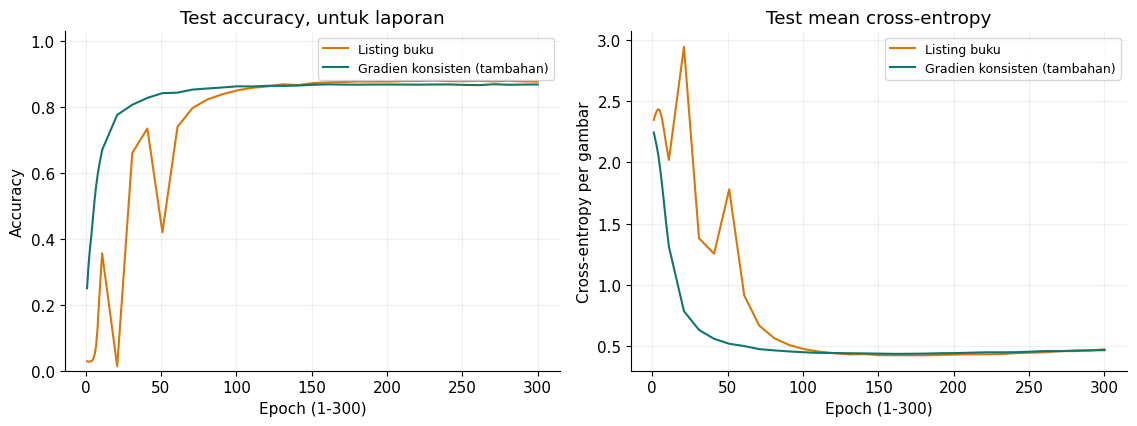

In [ ]:
# Grafik 6: dua program, geometri dan sampel training sama.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for name, history, color in [('Listing buku', book_history, '#d97706'),
                            ('Gradien konsisten (tambahan)', corrected_history, '#0f766e')]:
    epochs = [row['epoch'] for row in history]
    axes[0].plot(epochs, [row['test']['accuracy'] for row in history], color=color, label=name)
    axes[1].plot(epochs, [row['test']['cross_entropy'] for row in history], color=color, label=name)
axes[0].set(title='Test accuracy, untuk laporan', xlabel='Epoch (1-300)', ylabel='Accuracy', ylim=(0, 1.03))
axes[1].set(title='Test mean cross-entropy', xlabel='Epoch (1-300)', ylabel='Cross-entropy per gambar')
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 19. Hasil dan interpretasi

| Model, setelah 300 epoch | Train 896 | 104 dilewati | Validation | Test | Test mean CE |
| --- | --- | --- | --- | --- | --- |
| Listing buku | 96.88% | 88.46% | 87.00% | 87.74% | 0.472102 |
| Gradien konsisten (tambahan) | 97.21% | 90.38% | 86.60% | 86.83% | 0.465935 |

Nilai di atas dihitung dari model akhir yang dijalankan. Accuracy inference memakai bobot tetap dan dropout dimatikan. Pada listing buku, online akhir yang dibagi 1.000 adalah **81.40%**, sedangkan online pada 896 gambar yang benar-benar diproses adalah **90.85%**. Inference seluruh 1.000 gambar pada model yang sama adalah **96.00%**. Angka-angka tersebut tidak dapat dibandingkan tanpa menyebut denominator dan mode evaluasi.

Checkpoint final pada tabel buku adalah 87,74% test. Hasil run notebook setelah seluruh 300 epoch adalah **87.74%**. Selisih maksimum pada 12 checkpoint test yang dibandingkan adalah **0.000000**; status kesesuaian dalam toleransi yang dinyatakan: **sesuai**.

Finite difference memverifikasi gradien pendalaman terhadap loss yang didefinisikan, bukan terhadap tujuan mendapatkan angka test tertentu. Accuracy dan cross-entropy menjawab pertanyaan berbeda: benar atau salahnya kelas argmax versus probabilitas yang diberikan pada target.

Perbandingan dua program hanya memakai satu seed, geometri source, serta subset training yang sama. Tidak ada tuning learning rate atau checkpoint berdasarkan test; validation hanya dilaporkan. Perubahan cache, scaling, dan tanda digabung sehingga hasilnya tidak mengisolasi efek masing-masing perubahan.

Perbandingan CNN dengan Chapter 9 juga mengubah ukuran representasi, jumlah parameter, batch size, dan sampel efektif. Selisih score antarchapter belum membuktikan bahwa convolution sendiri menyebabkan seluruh peningkatan. Menambah layer tidak otomatis meningkatkan accuracy; konfigurasi dan evaluasi perlu diperiksa kembali.

## 20. Kernel dan feature map yang benar-benar dipelajari

Grafik berikut menampilkan **empat kernel pertama** dari listing buku setelah 300 epoch dan activation tanh-nya pada gambar training indeks 0. Pemilihan indeks kernel ditetapkan untuk visualisasi, bukan karena dianggap yang paling bagus. Kernel pada grafik berasal dari update sebenarnya, berbeda dari kernel edge buatan pada demonstrasi awal.

Bobot kecil/negatif/positif dapat dibaca sebagai kontribusi lokal, tetapi jangan langsung memberi label bahwa suatu kernel pasti mendeteksi garis atau sudut tertentu hanya dari gambar 3 × 3. Output bergantung juga pada patch input, tanh, dan bagaimana head menggunakan response di setiap posisi. Model tidak dilatih dengan label edge untuk masing-masing kernel.

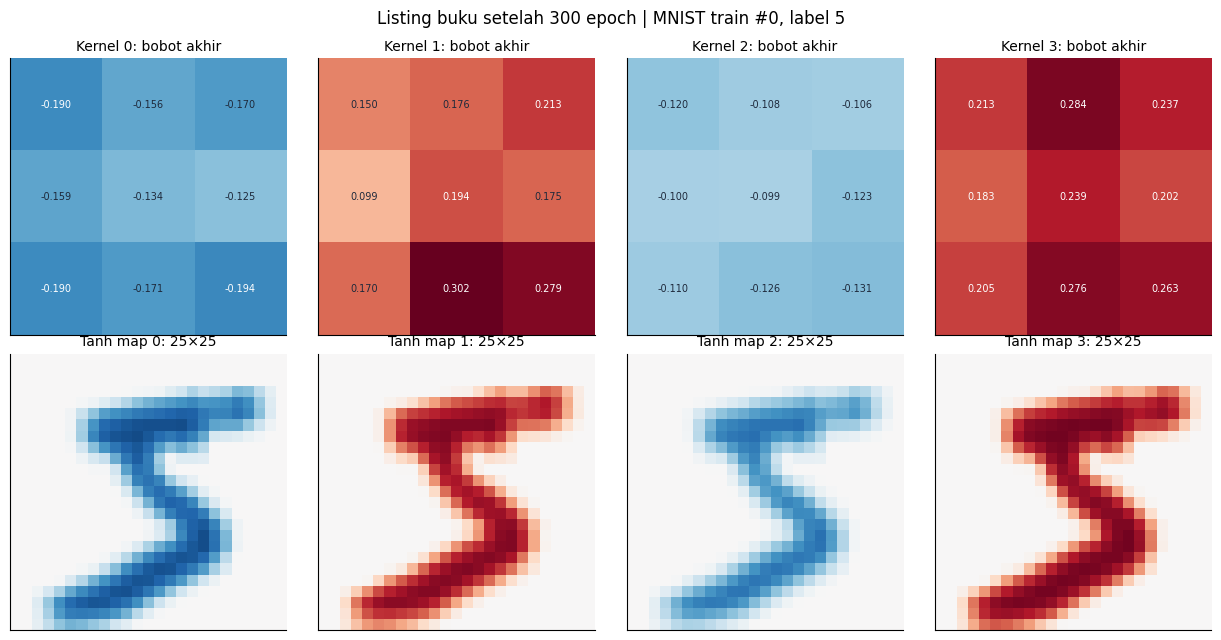

In [ ]:
# Grafik 7: empat kernel terlatih source dan respons tanh pada satu MNIST.
learned_kernel_maps = book_K.reshape(3, 3, 16)
sample_patches = extract_patches(images[0:1].reshape(1, 28, 28))
sample_feature_maps = tanh(sample_patches.reshape(-1, 9) @ book_K).reshape(25, 25, 16)
kernel_limit = float(np.max(np.abs(learned_kernel_maps[:, :, :4])))
fig, axes = plt.subplots(2, 4, figsize=(12.5, 6.5))
for f in range(4):
    axes[0, f].imshow(learned_kernel_maps[:, :, f], cmap='RdBu_r', vmin=-kernel_limit, vmax=kernel_limit)
    axes[0, f].set_title(f'Kernel {f}: bobot akhir', fontsize=10)
    for r in range(3):
        for c in range(3):
            value = learned_kernel_maps[r, c, f]
            axes[0, f].text(c, r, f'{value:.3f}', ha='center', va='center', fontsize=7,
                            color='white' if abs(value) > kernel_limit*0.6 else '#1e293b')
    axes[1, f].imshow(sample_feature_maps[:, :, f], cmap='RdBu_r', vmin=-1, vmax=1)
    axes[1, f].set_title(f'Tanh map {f}: 25×25', fontsize=10)
    for ax in axes[:, f]:
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle(f'Listing buku setelah 300 epoch | MNIST train #0, label {int(y_train[0])}', fontsize=12)
fig.tight_layout()
plt.show()

## 21. Kesalahan per kelas pada test

Confusion matrix menempatkan label sebenarnya pada baris dan prediksi pada kolom. Jumlah semua elemen adalah 10.000; jumlah diagonal harus sama dengan hitungan benar evaluator. Sel di luar diagonal memperlihatkan kelas yang tertukar.

Seluruh prediksi diambil dari model akhir tanpa dropout. Grafik ini digunakan untuk membaca hasil, bukan untuk mengubah parameter berdasarkan kelas test yang salah. Probabilitas softmax berjumlah satu, tetapi tidak otomatis membuktikan calibration.

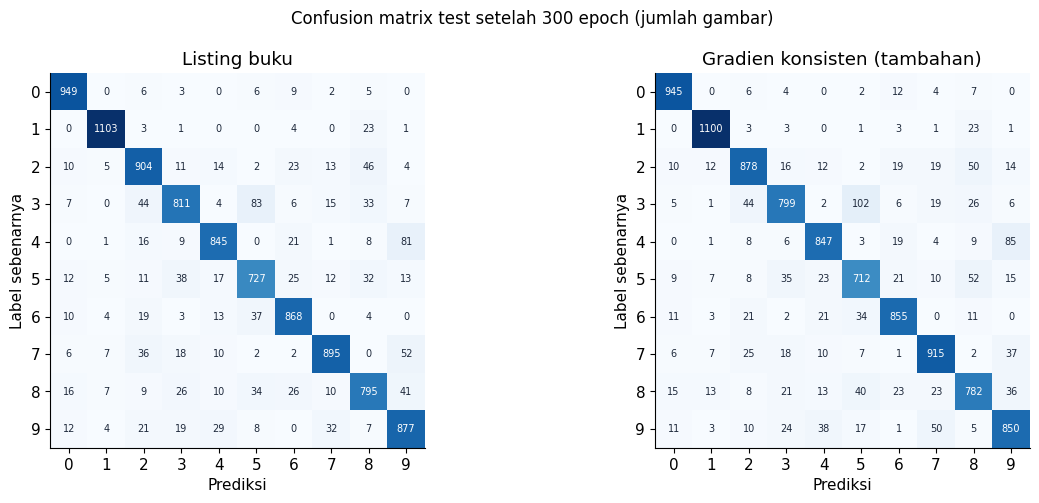

In [ ]:
# Grafik 8: confusion matrix dua model akhir, semua 10.000 test.
book_test_logits = cnn_inference_logits(test_images, book_K, book_W)
corrected_test_logits = cnn_inference_logits(test_images, corrected_K, corrected_W)
book_test_predictions = book_test_logits.argmax(axis=1)
corrected_test_predictions = corrected_test_logits.argmax(axis=1)
assert np.array_equal(book_test_predictions, softmax_stable(book_test_logits).argmax(axis=1))
confusion_matrices = []
for predictions, metrics in [(book_test_predictions, book_final),
                             (corrected_test_predictions, corrected_final)]:
    matrix = np.zeros((10, 10), dtype=int)
    np.add.at(matrix, (y_test, predictions), 1)
    assert matrix.sum() == 10000 and np.trace(matrix) == metrics['test']['correct']
    confusion_matrices.append(matrix)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.1))
vmax = max(matrix.max() for matrix in confusion_matrices)
for ax, matrix, title in zip(axes, confusion_matrices, ['Listing buku', 'Gradien konsisten (tambahan)']):
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=vmax)
    ax.set(title=title, xlabel='Prediksi', ylabel='Label sebenarnya', xticks=np.arange(10), yticks=np.arange(10))
    for r in range(10):
        for c in range(10):
            ax.text(c, r, str(matrix[r, c]), ha='center', va='center', fontsize=7,
                    color='white' if matrix[r, c] > vmax*0.55 else '#1e293b')
fig.suptitle('Confusion matrix test setelah 300 epoch (jumlah gambar)', fontsize=12)
fig.tight_layout()
plt.show()

## 22. Menyusun convolutional layer dan structure trick

Satu convolutional layer mengolah patch lokal menjadi beberapa channel feature. Layer berikutnya dapat melihat semua channel tersebut dalam receptive field lokal baru. Secara intuitif, susunan ini dapat membangun pola sederhana menjadi pola lebih kompleks: perbedaan pixel, garis, sudut, bagian bentuk, lalu representasi objek.

Untuk kernel 3 × 3, stride satu, dan dilation satu, receptive field teoritis pada input awal menjadi 3 × 3 setelah satu layer, 5 × 5 setelah dua layer, dan 7 × 7 setelah tiga layer. Ukuran tersebut menjelaskan area input yang bisa memengaruhi sebuah unit, bukan bukti bahwa seluruh area mempunyai pengaruh yang sama.

Nonlinearity antar-layer tetap penting. Rangkaian operasi linear saja masih merupakan pemetaan linear, walaupun parameter dan sparsity-nya mempunyai struktur. Training jaringan lebih dalam memerlukan perhatian pada gradien, initialization, kapasitas, dan data; peningkatan depth sendiri tidak menjamin peningkatan score.

Inti **structure trick** pada ringkasan buku adalah menggunakan parameter yang sama ketika kemampuan yang sama diperlukan pada beberapa tempat. CNN mengulang kernel di lokasi gambar; recurrent network dapat mengulang aturan transisi di waktu berbeda; embedding lookup memakai representasi token yang sama saat token itu muncul lagi. Prinsip reuse perlu mengikuti struktur tugas, bukan diterapkan tanpa alasan.

**Rujukan:** Trask (2019), hlm. 184-185. Receptive field berlapis merupakan pendalaman matematis; notebook tidak menambahkan training model bertingkat di luar listing sumber.